# Reliability diagrams from the tile output

Compares the coverage probabilities of any set of products verified with the tile notebooks (SPC outlooks, Chris's PPH, Cameron's grids). The products must have been run over the **same days and the same window**, so they share the same observations.

For each hazard, every product's forecast area is grouped by probability level:
- **Products drawn at SPC's levels** (outlooks, Chris's PPH) group on their own values.
- **Cameron's continuous probabilities** are binned down to SPC's levels (`to_level`).

The x position of each point is the **area-weighted mean forecast** in the group, not the bin's lower edge, so binning doesn't bias the diagram. The y value is the observed coverage, i.e. the share of the area within 40 km of a report. Whiskers are 90% intervals from resampling whole days. The lower panel shows sharpness: the share of the domain's area in each group, on a log scale.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Settings

In [2]:
D = os.path.expanduser('~/datasets')
OUT_DIR = f'{D}/reliability_figs'
os.makedirs(OUT_DIR, exist_ok=True)

HAZARDS = {'torn': dict(name='Tornado', obs='obs_ef0',   levels=[2, 5, 10, 15, 30, 45, 60]),
           'wind': dict(name='Wind',    obs='obs_50kt',  levels=[5, 15, 30, 45, 60, 75, 90]),
           'hail': dict(name='Hail',    obs='obs_1p0in', levels=[5, 15, 30, 45, 60, 75, 90])}

# label -> (tile folder, probability column, bin to SPC levels?, colour, marker)
COMPARISONS = {
    '2025, valid 12Z-12Z: SPC Day-1 outlooks vs Cameron': {
        'SPC outlook (1200)': (f'{D}/outlook_tiles_2025_1200', 'prob',         False, 'k',       'o'),
        'Cameron perfect':    (f'{D}/cameron_tiles_2025',      'prob_perfect', True,  '#1b9e77', 's'),
        'Cameron spccal':     (f'{D}/cameron_tiles_2025',      'prob_spccal',  True,  '#d95f02', '^'),
        'Cameron target':     (f'{D}/cameron_tiles_2025',      'prob_target',  True,  '#7570b3', 'v'),
    },
    '3 Mar - 30 Jun 2026, valid 12Z-12Z: SPC Day-1 outlooks vs Chris PPH': {
        'SPC outlook (1200)': (f'{D}/outlook_tiles_2026_1200', 'prob', False, 'k',       'o'),
        'Chris PPH (1200)':   (f'{D}/pph_tiles_2026_1200',     'prob', False, '#e7298a', 'D'),
    },
}
N_BOOT, SEED = 1000, 0

## Functions

`rel_table` sums, for each probability group: area A, observed area O, Σf·A (for the mean forecast), and the number of days. It also gives a day-bootstrap interval for O/A, using one set of resampled days for all groups.

In [3]:
def to_level(p, levels):
    lv = np.array([0] + list(levels), dtype=float)
    return lv[np.searchsorted(lv, np.asarray(p, dtype=float), side='right') - 1]

def load(folder, pcol, haz):
    t = pd.read_csv(f'{folder}/tiles_{haz}.csv', usecols=['date', 'area_km2', pcol, HAZARDS[haz]['obs']])
    return t.rename(columns={pcol: 'f', HAZARDS[haz]['obs']: 'O', 'area_km2': 'A'})

def rel_table(t, binned, haz, n_boot=N_BOOT, seed=SEED):
    t = t.assign(grp=to_level(t.f, HAZARDS[haz]['levels']) if binned else t.f, fA=t.f * t.A)
    days = np.sort(t.date.unique()); dix = {d: i for i, d in enumerate(days)}
    rng = np.random.default_rng(seed)
    W = np.stack([np.bincount(rng.integers(0, len(days), len(days)), minlength=len(days)) for _ in range(n_boot)])
    rows = []
    for g, d in t.groupby('grp'):
        dd = d.groupby('date')[['A', 'O']].sum()
        A = np.zeros(len(days)); O = np.zeros(len(days))
        idx = [dix[x] for x in dd.index]
        A[idx], O[idx] = dd.A.values, dd.O.values
        with np.errstate(invalid='ignore', divide='ignore'):
            boot = (W @ O) / (W @ A)
        lo, hi = np.nanpercentile(boot, [5, 95])
        rows.append(dict(level=g, A=d.A.sum(), O=d.O.sum(), fbar=d.fA.sum() / d.A.sum(),
                         obs_freq=d.O.sum() / d.A.sum(), lo=lo, hi=hi, n_days=int((A > 0).sum())))
    r = pd.DataFrame(rows)
    r['area_share'] = r.A / r.A.sum()
    return r

def bss(t):
    # Brier skill vs the sample climatology, from the exact (unbinned) probabilities
    f = t.f / 100
    N = t.A.sum(); ob = t.O.sum() / N
    bs = (f**2 * t.A - 2 * f * t.O + t.O).sum() / N
    return 1 - bs / (ob * (1 - ob))

## Figures

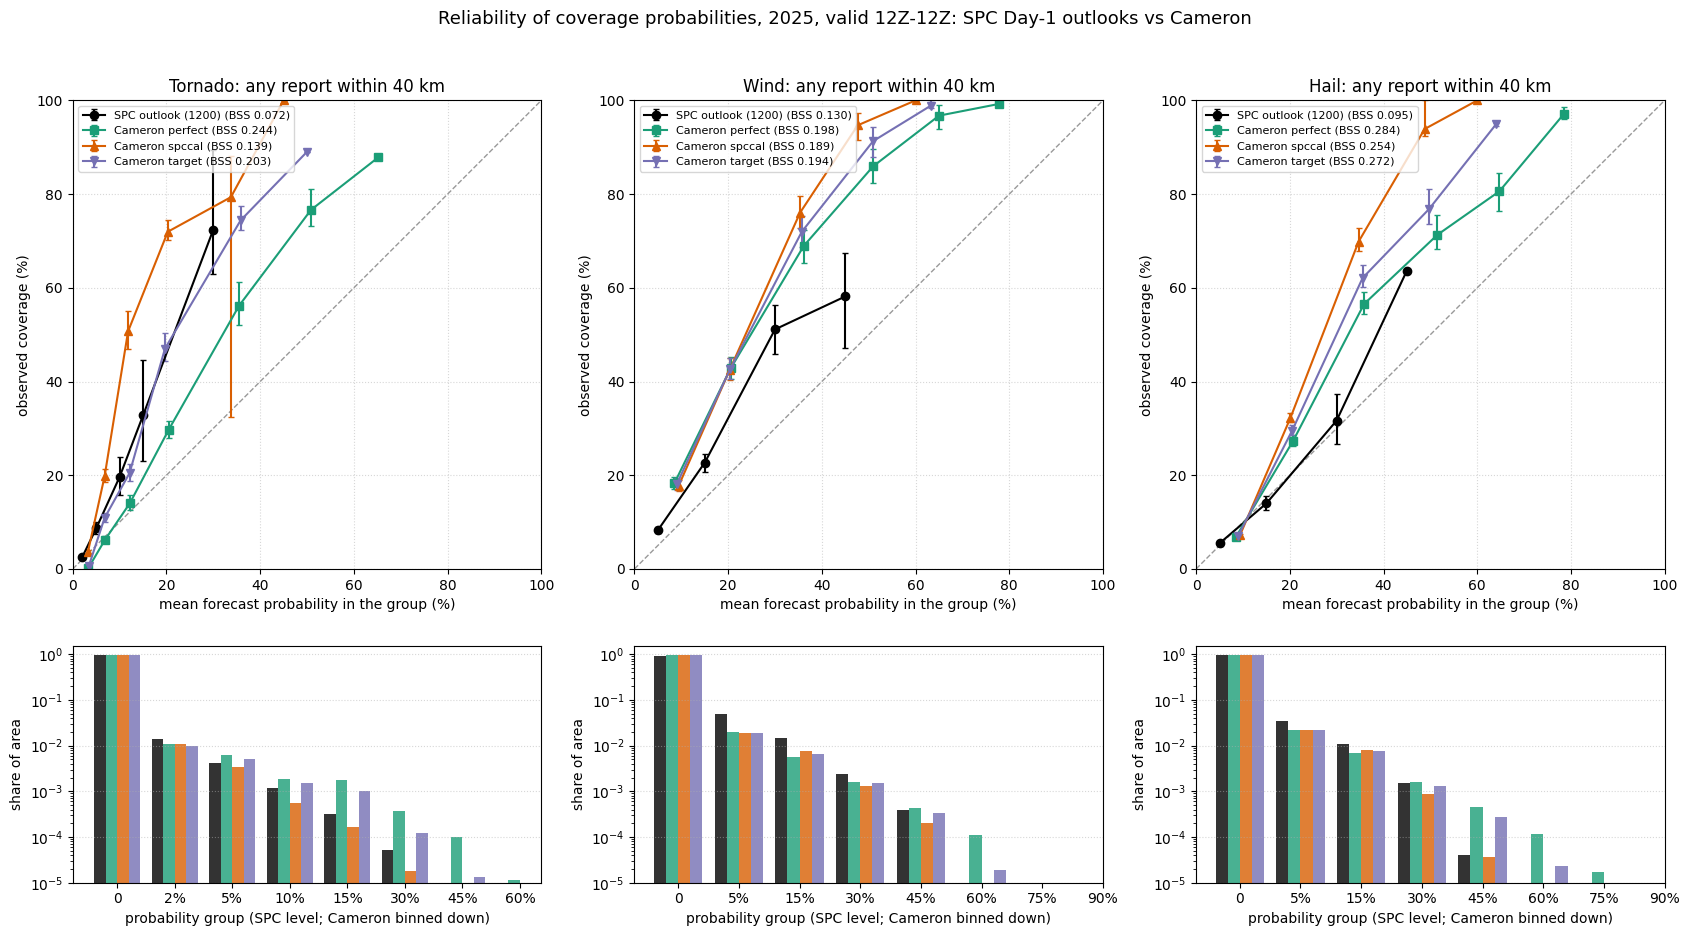

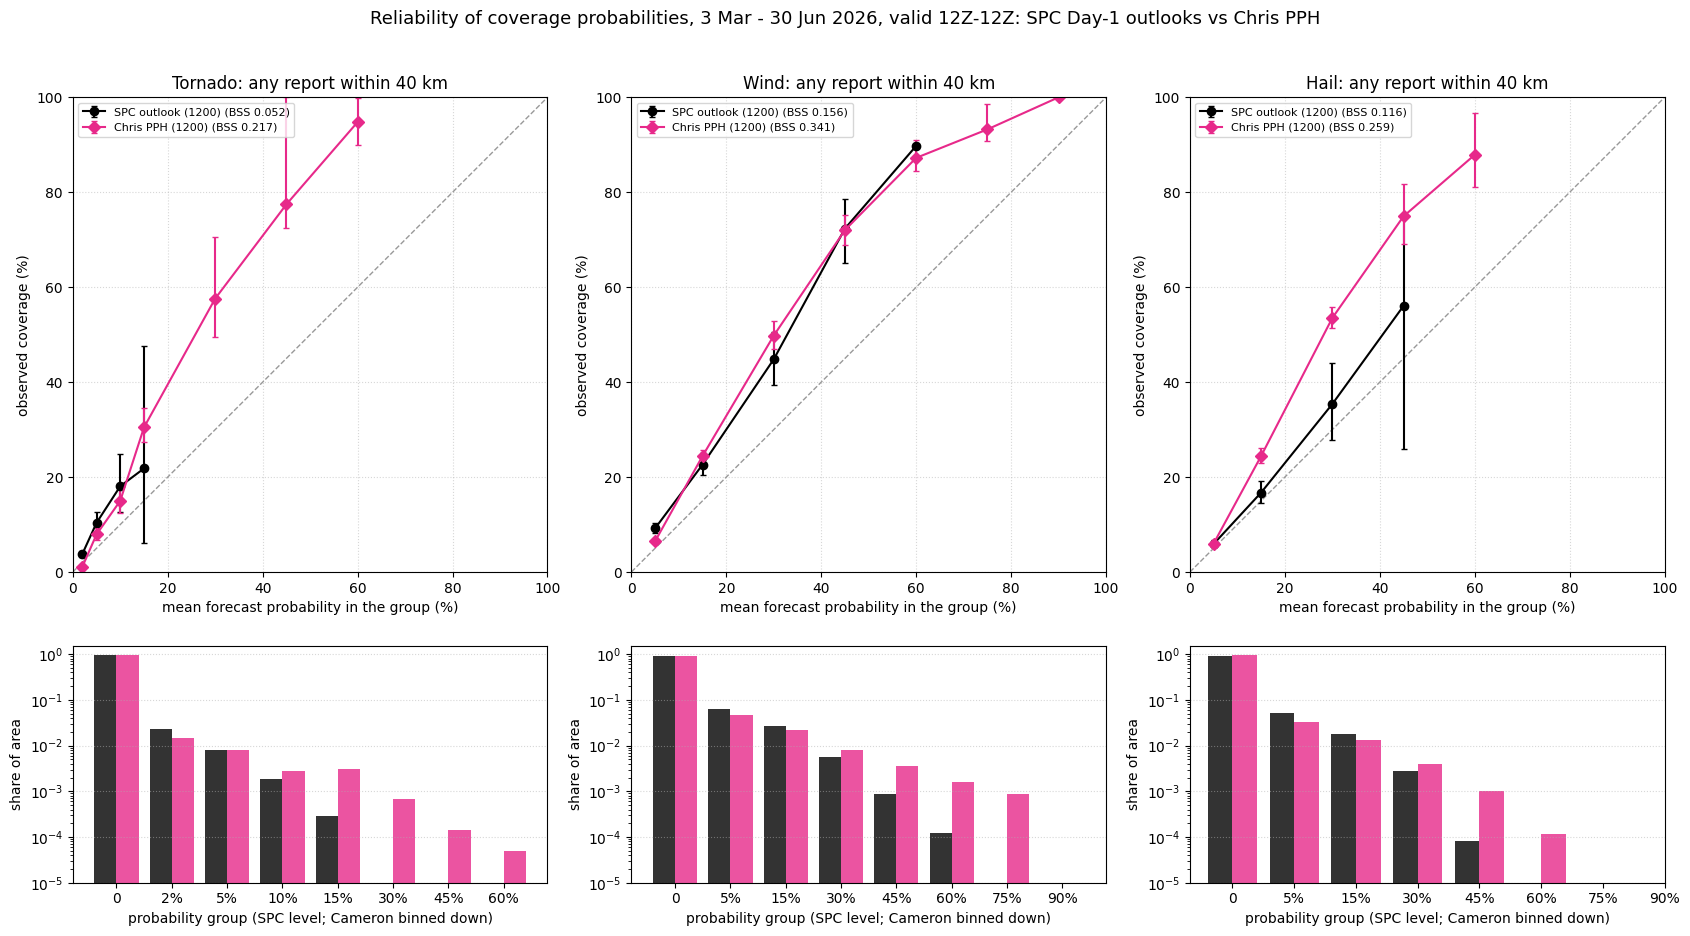

In [4]:
RESULTS = {}
for title, prods in COMPARISONS.items():
    fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), gridspec_kw=dict(height_ratios=[3, 1.2]))
    for j, (haz, spec) in enumerate(HAZARDS.items()):
        ax, ax2 = axes[0, j], axes[1, j]
        ax.plot([0, 100], [0, 100], color='0.6', ls='--', lw=1)
        width = 0.8 / len(prods)
        for k, (lab, (folder, pcol, binned, col, mk)) in enumerate(prods.items()):
            if not os.path.exists(f'{folder}/tiles_{haz}.csv'):
                print(f'missing: {folder}/tiles_{haz}.csv'); continue
            t = load(folder, pcol, haz)
            r = rel_table(t, binned, haz)
            RESULTS[(title, haz, lab)] = r
            p = r[r.level > 0]
            ax.errorbar(p.fbar, 100 * p.obs_freq, yerr=[100 * (p.obs_freq - p.lo).clip(lower=0), 100 * (p.hi - p.obs_freq).clip(lower=0)],
                        color=col, marker=mk, ms=6, lw=1.5, capsize=2, label=f'{lab} (BSS {bss(t):.3f})')
            pos = {lv: i for i, lv in enumerate([0] + spec['levels'])}
            ax2.bar([pos.get(lv, np.nan) + (k - (len(prods) - 1) / 2) * width for lv in r.level], r.area_share,
                    width, color=col, alpha=0.8)
        ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='mean forecast probability in the group (%)',
               ylabel='observed coverage (%)', title=f"{spec['name']}: any report within 40 km")
        ax.set_aspect('equal'); ax.grid(ls=':', alpha=0.5); ax.legend(fontsize=8, loc='upper left')
        ax2.set_yscale('log'); ax2.set_ylim(1e-5, 1.5)
        ax2.set_xticks(range(len(spec['levels']) + 1), ['0'] + [f'{l}%' for l in spec['levels']])
        ax2.set(xlabel='probability group (SPC level; Cameron binned down)', ylabel='share of area')
        ax2.grid(axis='y', ls=':', alpha=0.5)
    fig.suptitle(f'Reliability of coverage probabilities, {title}', fontsize=13)
    plt.tight_layout()
    fn = 'reliability_' + ('2025_cameron' if '2025' in title else '2026_pph_1200') + '.png'
    plt.savefig(f'{OUT_DIR}/{fn}', dpi=130)
    plt.show()

In [5]:
# the numbers behind the diagrams
tab = pd.concat({k: v for k, v in RESULTS.items()}, names=['comparison', 'hazard', 'product', 'row']).reset_index()
tab = tab[['comparison', 'hazard', 'product', 'level', 'n_days', 'fbar', 'obs_freq', 'lo', 'hi', 'area_share']]
tab.to_csv(f'{OUT_DIR}/reliability_tables.csv', index=False)
pd.set_option('display.width', 200)
for (c, h), d in tab.groupby(['comparison', 'hazard']):
    print(f'\n=== {c} | {h} ===')
    print(d.pivot_table(index='level', columns='product', values='obs_freq').mul(100).round(2))


=== 2025, valid 12Z-12Z: SPC Day-1 outlooks vs Cameron | hail ===
product  Cameron perfect  Cameron spccal  Cameron target  SPC outlook (1200)
level                                                                       
0.0                 0.01            0.01            0.01                0.10
5.0                 6.88            7.17            7.02                5.47
15.0               27.35           32.19           29.53               13.98
30.0               56.54           69.85           62.11               31.68
45.0               71.30           93.89           76.81               63.69
60.0               80.60          100.00           94.88                 NaN
75.0               97.18             NaN             NaN                 NaN

=== 2025, valid 12Z-12Z: SPC Day-1 outlooks vs Cameron | torn ===
product  Cameron perfect  Cameron spccal  Cameron target  SPC outlook (1200)
level                                                                       
0.0                